<a href="https://colab.research.google.com/github/RomanLuja/ML/blob/main/04_feature_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Заняття 4. Feature engineering: як створити ознаки, з якими модель працює краще

**Блок 2. Дані як основа ML**

## 1. Що таке ознака і навіщо її «конструювати»

Модель бачить лише **числа в колонках**. Вона не знає, що `2025-03-08 23:40` — це пізній вечір
свята, а `Shoes` — товар, який часто не підходить за розміром. **Feature engineering** — це
перекладання бізнес-знань у числові колонки.

| Сира колонка | Ознаки, які з неї можна зробити |
|---|---|
| дата й час замовлення | година, день тижня, місяць, «нічне замовлення», «вихідний» |
| категорія товару | по колонці 0/1 на кожну категорію (one-hot) |
| ціна і кількість | сума замовлення, сума знижки в грн |
| кількість попередніх замовлень | «перше замовлення» (0/1) |
| дата народження, дата найму | вік, стаж у роках |

**Правило:** найкращі ознаки народжуються з розуміння бізнесу. Запитайте себе: *«Від чого, на думку
людей з бізнесу, залежить результат?»*

## 2. Демонстрація: які замовлення повернуть

Інтернет-магазин втрачає гроші на поверненнях (доставка в обидва боки). Хоче заздалегідь знати
ризикові замовлення, щоб, наприклад, телефонувати й уточнювати розмір.

In [38]:
# Підготовка: бібліотеки та функція завантаження даних (працює в Colab і локально)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
DATA_URL = "https://raw.githubusercontent.com/KsiuTretyakova/ml_for_analys_dta_2026/refs/heads/main/data/"  # необов'язково: адреса теки з CSV (наприклад, raw-посилання на GitHub)


def load_csv(name):
    """Читає CSV з поточної теки, з теки data/, з DATA_URL або просить завантажити файл у Colab."""
    for path in (name, os.path.join("data", name)):
        if os.path.exists(path):
            return pd.read_csv(path)
    if DATA_URL:
        return pd.read_csv(DATA_URL.rstrip("/") + "/" + name)
    from google.colab import files
    print(f"Натисніть «Choose files» і виберіть файл {name}")
    files.upload()
    return pd.read_csv(name)

In [39]:
orders = load_csv("online_orders.csv")
print(orders.shape, "| частка повернень:", round(orders["returned"].mean(), 3))
orders.head()

(8000, 13) | частка повернень: 0.272


,order_id,customer_id,order_datetime,category,price_uah,quantity,discount_pct,delivery_city,delivery_days,payment_method,device,customer_prev_orders,returned
0,O705785,U3382,2025-01-01 00:29,Books,721.0,1,0,Kyiv,5,card,mobile,0,1
1,O703152,U1169,2025-01-01 01:12,Clothing,1033.0,1,10,Other,7,cash_on_delivery,app,2,1
2,O702804,U3610,2025-01-01 02:08,Shoes,1808.0,1,20,Other,5,card,mobile,4,0
3,O704501,U2704,2025-01-01 03:19,Clothing,982.0,1,5,Odesa,4,cash_on_delivery,desktop,1,1
4,O701323,U1515,2025-01-01 03:19,Electronics,14470.0,1,5,Kyiv,5,cash_on_delivery,mobile,4,0


### Як порівнювати моделі: ROC-AUC

Сьогодні порівнюватимемо моделі за **ROC-AUC *(Receiver Operating Characteristic — Area Under Curve)***. Поки що достатньо простого розуміння:

> Візьмемо випадкове замовлення, яке повернули, і випадкове, яке не повернули.
> ROC-AUC — імовірність того, що модель дасть першому вищий «ризик», ніж другому.

0.5 — модель вгадує навмання, 1.0 — ідеально.

### Крок 1. Модель «як є» — лише готові числові колонки

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

train, test = train_test_split(orders, test_size=0.25, random_state=42, stratify=orders["returned"])

raw_num = ["price_uah", "quantity", "discount_pct", "delivery_days", "customer_prev_orders"]
lr_raw = LogisticRegression(max_iter=1000).fit(train[raw_num], train["returned"])
auc_raw = roc_auc_score(test["returned"], lr_raw.predict_proba(test[raw_num])[:, 1])
print(f"ROC-AUC лише на сирих числових колонках: {auc_raw:.3f}")

ROC-AUC лише на сирих числових колонках: 0.640


`predict_proba(...)[:, 1]` — це оцінка ймовірності класу 1 («повернуть») для кожного замовлення.

### Крок 2. Створюємо ознаки

Пишемо **одну функцію**, яка додає ознаки. Її застосуємо і до навчальних, і до нових даних.

In [41]:
def add_order_features(df):
    df = df.copy()
    dt = pd.to_datetime(df["order_datetime"])
    df["hour"] = dt.dt.hour
    df["weekday"] = dt.dt.day_of_week                       # 0 - понеділок
    df["is_weekend"] = (df["weekday"] >= 5).astype(int)
    df["is_night"] = ((df["hour"] >= 23) | (df["hour"] < 5)).astype(int)
    df["order_value_uah"] = df["price_uah"] * df["quantity"]
    df["discount_uah"] = df["order_value_uah"] * df["discount_pct"] / 100
    df["is_first_order"] = (df["customer_prev_orders"] == 0).astype(int)
    df["is_loyal"] = (df["customer_prev_orders"] > 3).astype(int)
    df["multi_items"] = (df["quantity"] > 1).astype(int)
    return df

train_f = add_order_features(train)
test_f = add_order_features(test)
train_f[["order_datetime", "hour", "is_night", "order_value_uah", "discount_uah", "is_first_order"]].head()

,order_datetime,hour,is_night,order_value_uah,discount_uah,is_first_order
2347,2025-04-16 19:36,19,0,1115.0,111.5,0
7604,2025-12-13 15:00,15,0,4414.0,441.4,0
7074,2025-11-19 07:38,7,0,13540.0,2708.0,0
3723,2025-06-17 04:49,4,1,490.0,24.5,0
4097,2025-07-03 19:12,19,0,949.0,0.0,0


### Крок 3. Категорії: one-hot кодування

`category = Shoes` перетворюється на колонку `category_Shoes = 1`, а решта колонок категорій — 0.
`handle_unknown="ignore"` — якщо в нових даних з'явиться нова категорія, модель не впаде.

In [42]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe.fit(train_f[["category"]])
pd.DataFrame(ohe.transform(train_f[["category"]].head()), columns=ohe.get_feature_names_out())

,category_Beauty,category_Books,category_Clothing,category_Electronics,category_Home,category_Shoes
0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0


In [43]:
train_f.head()

,order_id,customer_id,order_datetime,category,price_uah,quantity,discount_pct,delivery_city,delivery_days,payment_method,device,customer_prev_orders,returned,hour,weekday,is_weekend,is_night,order_value_uah,discount_uah,is_first_order,is_loyal,multi_items
2347,O707049,U4574,2025-04-16 19:36,Clothing,1115.0,1,10,Dnipro,1,card,desktop,5,1,19,2,0,0,1115.0,111.5,0,1,0
7604,O703582,U4701,2025-12-13 15:00,Home,2207.0,2,10,Kyiv,2,card,mobile,8,1,15,5,1,0,4414.0,441.4,0,1,1
7074,O707429,U4287,2025-11-19 07:38,Electronics,6770.0,2,20,Kyiv,4,card,app,7,0,7,2,0,0,13540.0,2708.0,0,1,1
3723,O700370,U4901,2025-06-17 04:49,Books,490.0,1,5,Odesa,4,cash_on_delivery,mobile,1,0,4,1,0,1,490.0,24.5,0,0,0
4097,O707878,U4130,2025-07-03 19:12,Home,949.0,1,0,Kyiv,4,card,app,11,0,19,3,0,0,949.0,0.0,0,1,0


### Крок 4. Збираємо все в Pipeline

Обробок стає багато: числові колонки треба масштабувати (логістична регресія чутлива до масштабу),
категорії — кодувати. Робити це вручну для train і test — шлях до помилок.

- `ColumnTransformer` — «яку обробку застосувати до яких колонок»;
- `Pipeline` — «обробка → модель» як один об'єкт з методами `fit` і `predict`.

Pipeline сам навчає обробку лише на train (`fit`) — витоку немає.

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

num_features = ["price_uah", "quantity", "discount_pct", "delivery_days", "customer_prev_orders",
                "hour", "is_weekend", "is_night", "order_value_uah", "discount_uah",
                "is_first_order", "is_loyal", "multi_items"]
cat_features = ["category", "delivery_city", "payment_method", "device"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])
model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000)),
])
model.fit(train_f, train_f["returned"])
auc_fe = roc_auc_score(test_f["returned"], model.predict_proba(test_f)[:, 1])
print(f"ROC-AUC: сирі колонки {auc_raw:.3f} -> після feature engineering {auc_fe:.3f}")

ROC-AUC: сирі колонки 0.640 -> після feature engineering 0.743


Та сама модель, ті самі рядки — але завдяки ознакам якість помітно вища. **Ознаки часто важать
більше, ніж вибір моделі.**

Подивимося, які ознаки модель вважає найважливішими (коефіцієнти після масштабування можна
порівнювати між собою: більше за модулем — сильніший вплив).

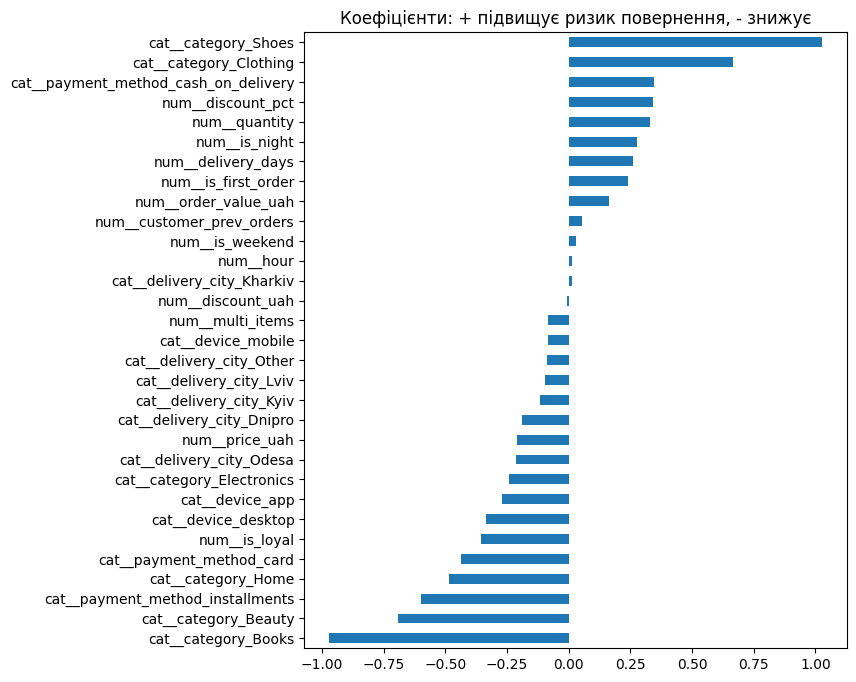

In [45]:
coefs = pd.Series(model.named_steps["clf"].coef_[0],
                  index=model.named_steps["prep"].get_feature_names_out()).sort_values()
coefs.plot.barh(figsize=(7, 8), title="Коефіцієнти: + підвищує ризик повернення, - знижує")
plt.show()

Взуття й одяг, оплата при отриманні, нічні замовлення, перші замовлення підвищують ризик; книги й
постійні клієнти — знижують. Ці висновки бізнес може перевірити здоровим глуздом.

### Крок 5. Модель для нового замовлення

Pipeline приймає «сирі» колонки — нове замовлення просто проходить ту саму функцію ознак.

In [46]:
new_order = pd.DataFrame([{
    "order_id": "O-NEW", "customer_id": "U1", "order_datetime": "2026-01-10 23:55",
    "category": "Shoes", "price_uah": 2400, "quantity": 2, "discount_pct": 30,
    "delivery_city": "Other", "delivery_days": 5, "payment_method": "cash_on_delivery",
    "device": "mobile", "customer_prev_orders": 0,
}])
risk = model.predict_proba(add_order_features(new_order))[:, 1][0]
print(f"Оцінка ризику повернення: {risk:.0%}")

Оцінка ризику повернення: 92%


### Обережно: витік через ознаки

Спокуслива ознака — «частка повернень цього клієнта». Якщо порахувати її по **всіх** даних,
вона містить відповідь для поточного замовлення. Такі ознаки рахують лише за **минулими** подіями
до моменту прогнозу. Перевіряйте кожну нову ознаку тим самим запитанням: *«Чи знатиму я це в момент
прогнозу?»*

---
## 3. Практика: хто з працівників звільниться

HR-відділ хоче знати, кому з працівників варто запропонувати розмову про розвиток, щоб зменшити
плинність. Дані `hr_attrition.csv` — знімок на `2025-12-31`; ціль — `left_company`.

### Завдання 1. Огляд і орієнтир

Завантажте дані, подивіться на типи колонок і частку тих, хто звільнився. Розділіть на train/test
(25 %, `random_state=42`, `stratify`). Навчіть `LogisticRegression(max_iter=1000)` лише на готових
числових колонках (без дат і `department`) і порахуйте ROC-AUC.

In [47]:
# 1. Завантаження й огляд
hr = load_csv("hr_attrition.csv")
print(hr.shape)
print(hr.dtypes)
print("\nЧастка звільнених:\n", round(hr["left_company"].mean(), 3))

# 2. Готові числові ознаки (без цілі; дати й department мають тип object, тож відпадають)
X = hr.select_dtypes(include="number").drop(columns=["left_company"])
y = hr["left_company"]
print("Ознаки:", X.columns.tolist())
print("Пропусків:", X.isna().sum().sum())

# 3. Train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 4. Модель і ROC-AUC
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

(4000, 15)
employee_id              object
birth_date               object
hire_date                object
department               object
job_level                 int64
monthly_salary_uah      float64
last_raise_date          object
overtime_hours_month      int64
remote_days_week          int64
satisfaction_score        int64
performance_score         int64
commute_km              float64
trainings_last_year       int64
manager_changes_2y        int64
left_company              int64
dtype: object

Частка звільнених:
 0.136
Ознаки: ['job_level', 'monthly_salary_uah', 'overtime_hours_month', 'remote_days_week', 'satisfaction_score', 'performance_score', 'commute_km', 'trainings_last_year', 'manager_changes_2y']
Пропусків: 0
ROC-AUC: 0.738


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Датасет містить 4000 рядків і 15 колонок. Дати (birth_date, hire_date, last_raise_date), employee_id та department мають тип object, тому в базову модель не потрапили. Частка тих, хто звільнився, становить 0.1358 (13.58 %), класи незбалансовані. Дані розділено на train/test у пропорції 75/25 з random_state=42 і stratify. Логістична регресія (max_iter=1000) на 9 числових ознаках дала ROC-AUC = 0.738 на test. Це орієнтир, з яким порівнюватимемо моделі з новими ознаками.

In [48]:
hr = load_csv("hr_attrition.csv")
# Ваш код тут
print(hr.dtypes)
print("\nЧастка звільнень:", round(hr['left_company'].mean(), 3), "\n")
hr.head()


employee_id              object
birth_date               object
hire_date                object
department               object
job_level                 int64
monthly_salary_uah      float64
last_raise_date          object
overtime_hours_month      int64
remote_days_week          int64
satisfaction_score        int64
performance_score         int64
commute_km              float64
trainings_last_year       int64
manager_changes_2y        int64
left_company              int64
dtype: object

Частка звільнень: 0.136 



,employee_id,birth_date,hire_date,department,job_level,monthly_salary_uah,last_raise_date,overtime_hours_month,remote_days_week,satisfaction_score,performance_score,commute_km,trainings_last_year,manager_changes_2y,left_company
0,E3000,1992-03-11,2021-02-25,Support,1,14600.0,2025-11-01,33,2,2,5,13.8,1,0,0
1,E3001,2000-04-22,2025-03-29,Support,4,41900.0,2025-06-04,39,0,3,3,7.3,0,0,0
2,E3002,1992-11-02,2025-04-11,Support,2,22100.0,2025-05-05,10,0,4,3,22.8,0,0,0
3,E3003,1986-10-18,2021-04-18,IT,1,27200.0,2024-08-08,15,3,2,4,22.2,2,0,1
4,E3004,1995-10-04,2025-10-27,Sales,2,34900.0,2025-11-01,13,5,4,3,11.3,0,0,0


In [49]:
hr_train, hr_test = train_test_split(hr, test_size=0.25, random_state=42, stratify=hr['left_company'])

hr_raw = ['job_level', 'monthly_salary_uah', 'overtime_hours_month',
          'remote_days_week', 'satisfaction_score', 'performance_score',
          'commute_km', 'trainings_last_year', 'manager_changes_2y']

base = Pipeline([
    ('sc', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

base.fit(hr_train[hr_raw], hr_train['left_company'])

auc_hr_raw = roc_auc_score(hr_test['left_company'], base.predict_proba(hr_test[hr_raw])[:,1])
print(f"ROC-AUC for raw: {auc_hr_raw:.3f}")

ROC-AUC for raw: 0.739


### Завдання 2. Ознаки з дат і бізнес-ознаки

Напишіть функцію `add_hr_features(df)`, що додає:
- `age` — вік у роках на `2025-12-31`;
- `tenure_years` — стаж у компанії;
- `months_since_raise` — місяців від останнього підвищення;
- `salary_vs_dept` — зарплата, поділена на медіанну зарплату свого відділу;
- `long_commute_office` — 1, якщо дорога > 20 км і віддалених днів ≤ 1.

*Підказка:* різниця дат дає `Timedelta`; `.dt.days / 365.25` — роки.
Медіану відділу для `salary_vs_dept` рахуйте за `groupby(...).transform("median")`.

In [50]:
# Ваш код тут
SNAPSHOT = pd.Timestamp('2025-12-31')


def add_hr_features(df):
    df = df.copy()
    df['age'] = (SNAPSHOT - pd.to_datetime(df['birth_date'])).dt.days / 365.25
    df['tenure_years'] = (SNAPSHOT - pd.to_datetime(df['hire_date'])).dt.days / 365.25
    df['months_since_raise'] = (SNAPSHOT - pd.to_datetime(df['last_raise_date'])).dt.days / 30.4
    df['salary_vs_dept'] = df['monthly_salary_uah'] / df.groupby('department')['monthly_salary_uah'].transform("median")
    df['long_commute_office'] = ((df['commute_km'] > 20) & (df['remote_days_week'] <= 1)).astype(int)
    return df

hr_train_f = add_hr_features(hr_train)
hr_test_f = add_hr_features(hr_test)

hr_train_f[['age', 'tenure_years', 'months_since_raise', 'salary_vs_dept', 'long_commute_office']].describe().round(2)

,age,tenure_years,months_since_raise,salary_vs_dept,long_commute_office
count,3000.00,3000.00,3000.00,3000.00,3000.00
mean,33.23,2.65,11.16,1.08,0.08
std,6.26,2.13,7.78,0.36,0.28
min,20.04,0.08,0.00,0.43,0.00
25%,28.86,1.08,4.93,0.78,0.00
50%,33.14,2.12,9.87,1.00,0.00
75%,37.44,3.61,14.80,1.30,0.00
max,58.35,19.16,57.24,2.71,1.00


### Завдання 3. Pipeline з категоріями

Зберіть `Pipeline`: `StandardScaler` для числових колонок (сирі + нові), `OneHotEncoder` для
`department`, модель `LogisticRegression(max_iter=1000)`. Порахуйте ROC-AUC і порівняйте із
завданням 1.

In [54]:
# Ваш код тут
hr_num = hr_raw + ['age', 'tenure_years', 'months_since_raise', 'salary_vs_dept', 'long_commute_office']

hr_model = Pipeline([
    ('prep', ColumnTransformer([
        ('num', StandardScaler(), hr_num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['department'])
    ])),
    ('model', LogisticRegression(max_iter=1000))
])

hr_model.fit(hr_train_f, hr_train_f['left_company'])

auc_hr_fe = roc_auc_score(hr_test_f['left_company'], hr_model.predict_proba(hr_test_f)[:,1])
print(f"ROC-AUC: {auc_hr_raw:.3f} -> {auc_hr_fe:.3f}")

ROC-AUC: 0.739 -> 0.777


### Завдання 4. Що впливає на звільнення

Побудуйте графік коефіцієнтів моделі (як у демонстрації). Назвіть три фактори, що найбільше
підвищують ризик звільнення, і три, що знижують. Чи погоджуєтеся ви з ними як людина, яка розуміє HR?

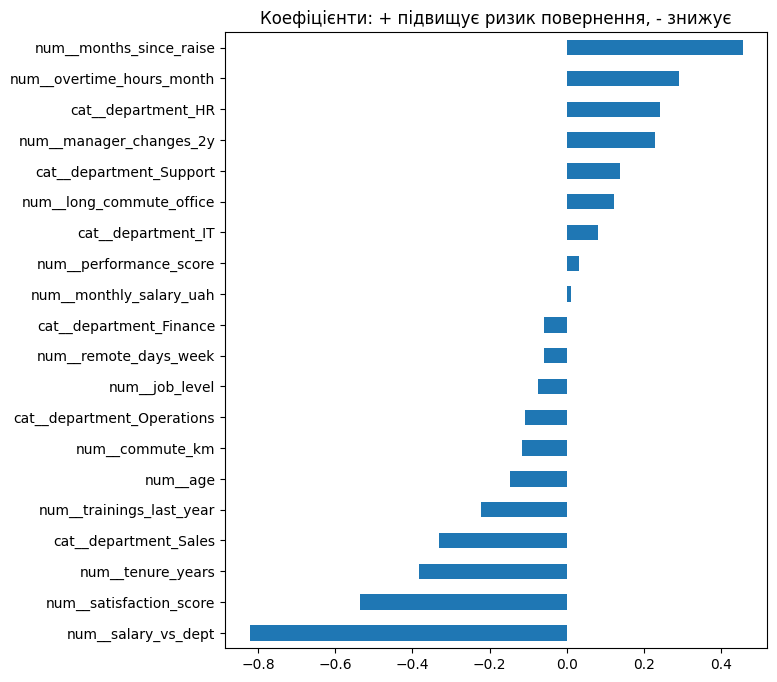

In [55]:
# Підвищують ризик: довго без підвищення, переробки, часті зміни керівника.
# Знижують: зарплата вища за медіану відділу, задоволеність, стаж у компанії.
# Ваш код тут

hr_coefs = pd.Series(hr_model.named_steps["model"].coef_[0],
                  index=hr_model.named_steps["prep"].get_feature_names_out()).sort_values()
hr_coefs.plot.barh(figsize=(7, 8), title="Коефіцієнти: + підвищує ризик повернення, - знижує")
plt.show()

### Завдання 5 (додатково). Подумайте про витік

Медіану зарплати у відділі ми рахували окремо в train і в test. Чи є тут витік цілі? А якби ми
додали ознаку «частка звільнених у відділі», порахувавши її по всіх даних? Відповідайте в
коментарі.

In [53]:
# Медіана зарплати не містить цілі - витоку цілі немає (хоча строго її краще рахувати лише на train
# і зберігати для нових даних). «Частка звільнених у відділі» по всіх даних містить left_company
# поточного працівника і test-даних - це витік. Рахувати її можна лише за минулими періодами.
# Ваш код тут

---
## Підсумок

- Ознаки — це бізнес-знання, перекладені в числа. Вони часто важать більше, ніж модель.
- Дати → компоненти й різниці; категорії → one-hot; суми, частки, прапорці → з наявних колонок.
- `ColumnTransformer` + `Pipeline` — один об'єкт «обробка + модель», без витоку.
- Кожну нову ознаку перевіряємо: *«Чи знатиму я це в момент прогнозу?»*